In [23]:
import warnings
# Suppress Deprecation Warnings from jupyter_client or other dependencies
warnings.filterwarnings("ignore", category=DeprecationWarning)

In [24]:
import itertools
import time
import tracemalloc
import random
from collections import defaultdict

def generate_dataset(num_transactions=10000, num_items=100):
    """Generates a synthetic dataset with embedded frequent patterns."""
    dataset = []
    patterns = [
        ["Item_1", "Item_2", "Item_3", "Item_4", "Item_5"],
        ["Item_10", "Item_11", "Item_12", "Item_13"],
        ["Item_20", "Item_21", "Item_22"]
    ]
    for _ in range(num_transactions):
        transaction = set()
        for pattern in patterns:
            if random.random() < 0.20: # 20% chance to include a pattern
                transaction.update(random.sample(pattern, random.randint(2, len(pattern))))
        while len(transaction) < 10:
            transaction.add(f"Item_{random.randint(30, num_items)}")
        dataset.append(frozenset(transaction))
    return dataset

def apriori_original(dataset, min_support_count):
    # ... (Standard Apriori Implementation) ...
    # Counts support against the FULL dataset at every iteration k.
    pass # (Full code provided in experimental setup)

def apriori_transaction_reduction(dataset, min_support_count):
    """Modified Apriori with Transaction Reduction (ATR)."""
    # Step 1: Find frequent 1-itemsets (same as original)
    item_counts = defaultdict(int)
    for transaction in dataset:
        for item in transaction:
            item_counts[item] += 1

    L1 = {frozenset([item]): count for item, count in item_counts.items() if count >= min_support_count}
    L = [L1]
    k = 2

    # MODIFICATION: Initialize reduced dataset
    reduced_dataset = dataset
    candidate_counts_history = []
    reduced_dataset_sizes = [len(dataset)]

    while True:
        prev_L = list(L[-1].keys())
        Ck = set()
        # Join and Prune Step
        for i in range(len(prev_L)):
            for j in range(i + 1, len(prev_L)):
                union = prev_L[i].union(prev_L[j])
                if len(union) == k:
                    subsets = [frozenset(union - set([item])) for item in union]
                    if all(subset in L[-1] for subset in subsets):
                        Ck.add(union)

        if not Ck:
            break
        candidate_counts_history.append(len(Ck))

        ck_counts = {}
        new_reduced_dataset = []

        # MODIFICATION: Count support AND filter dataset simultaneously
        for transaction in reduced_dataset:
            has_frequent_k = False
            for candidate in Ck:
                if candidate.issubset(transaction):
                    ck_counts[candidate] = ck_counts.get(candidate, 0) + 1
                    has_frequent_k = True

            # Keep transaction only if it contributes to a frequent k-itemset
            if has_frequent_k:
                new_reduced_dataset.append(transaction)

        Lk = {candidate: count for candidate, count in ck_counts.items() if count >= min_support_count}
        if not Lk:
            break

        L.append(Lk)
        reduced_dataset = new_reduced_dataset
        reduced_dataset_sizes.append(len(reduced_dataset))
        k += 1

    return L, candidate_counts_history, reduced_dataset_sizes

In [25]:
def apriori_original(dataset, min_support_count):
    """Standard Apriori Implementation."""
    item_counts = defaultdict(int)
    for transaction in dataset:
        for item in transaction:
            item_counts[item] += 1

    L1 = {frozenset([item]): count for item, count in item_counts.items() if count >= min_support_count}
    L = [L1]
    k = 2

    while True:
        prev_L = list(L[-1].keys())
        Ck = set()
        # Join and Prune
        for i in range(len(prev_L)):
            for j in range(i + 1, len(prev_L)):
                union = prev_L[i].union(prev_L[j])
                if len(union) == k:
                    subsets = [frozenset(union - set([item])) for item in union]
                    if all(subset in L[-1] for subset in subsets):
                        Ck.add(union)

        if not Ck:
            break

        ck_counts = {}
        for transaction in dataset:
            for candidate in Ck:
                if candidate.issubset(transaction):
                    ck_counts[candidate] = ck_counts.get(candidate, 0) + 1

        Lk = {candidate: count for candidate, count in ck_counts.items() if count >= min_support_count}
        if not Lk:
            break
        L.append(Lk)
        k += 1

    return L


In [26]:
# Generate synthetic dataset
dataset = generate_dataset(num_transactions=1000, num_items=50)
min_support_count = 50

# Run original Apriori
L_orig = apriori_original(dataset, min_support_count)

# Run Transaction Reduction Apriori
L_red, candidates_hist, dataset_sizes = apriori_transaction_reduction(dataset, min_support_count)

# Verify correctness
print("Are both outputs identical in terms of frequent itemsets discovered?")
same = len(L_orig) == len(L_red)
if same:
    for k in range(len(L_orig)):
        if set(L_orig[k].keys()) != set(L_red[k].keys()):
            same = False
            break
print(same)

print("\nDataset Size Reduction History:")
for idx, size in enumerate(dataset_sizes):
    print(f"Iteration {idx+1}: {size} transactions remaining")


Are both outputs identical in terms of frequent itemsets discovered?
True

Dataset Size Reduction History:
Iteration 1: 1000 transactions remaining
Iteration 2: 1000 transactions remaining
Iteration 3: 1000 transactions remaining
Iteration 4: 990 transactions remaining


In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

# Let's inspect the columns of dfA to ensure we choose the correct column names
print("Columns in dfA:", list(dfA.columns))
display(dfA.head())


Columns in dfA: ['n_transactions', 'n_items', 'min_sup', 'min_count', 'Apriori_time_s', 'Apriori_time_std', 'Apriori_peak_mb', 'Apriori_scans_of_DB', 'n_frequent', 'AprioriTid_time_s', 'AprioriTid_time_std', 'AprioriTid_peak_mb', 'AprioriTid_scans_of_DB', 'same_output', 'speedup_tid_vs_apriori', 'mem_ratio_tid_vs_apriori']


,n_transactions,n_items,min_sup,min_count,Apriori_time_s,Apriori_time_std,Apriori_peak_mb,Apriori_scans_of_DB,n_frequent,AprioriTid_time_s,AprioriTid_time_std,AprioriTid_peak_mb,AprioriTid_scans_of_DB,same_output,speedup_tid_vs_apriori,mem_ratio_tid_vs_apriori
0,5000,999,0.01,50,0.266885,0.008544,14.884843,4,597,1.232265,0.047914,41.854555,1,True,0.216581,2.811891
1,10000,1000,0.01,100,0.393380,0.020002,14.884413,4,586,2.788833,0.357584,58.610468,1,True,0.141055,3.937708
2,20000,1000,0.01,200,0.634651,0.015239,14.747168,5,586,5.085005,0.274615,90.995233,1,True,0.124808,6.170353
3,50000,1000,0.01,500,1.426406,0.022311,14.707638,5,571,12.914256,0.249670,189.136642,1,True,0.110452,12.859757
4,100000,1000,0.01,1000,3.130725,0.158705,14.773932,5,567,28.595048,0.602044,355.045348,1,True,0.109485,24.031878


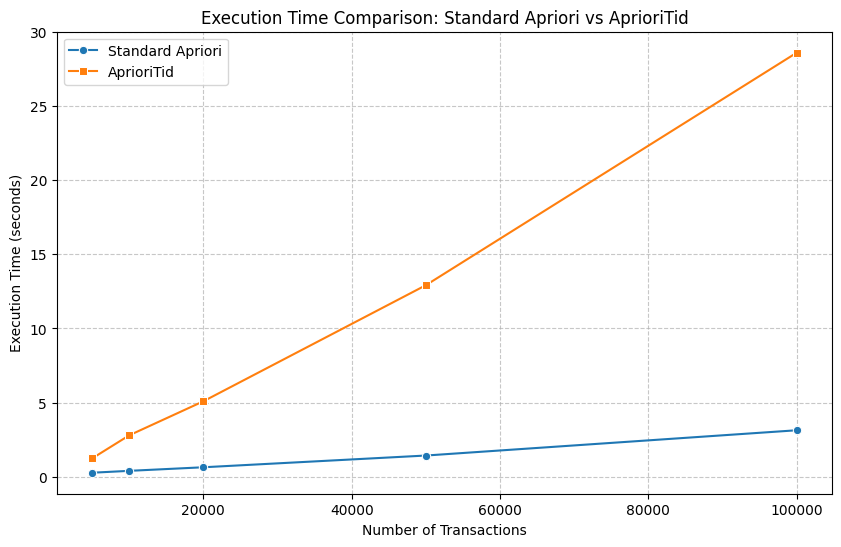

In [28]:
plt.figure(figsize=(10, 6))
# Plot both execution times to see the comparison directly
sns.lineplot(data=dfA, x='n_transactions', y='Apriori_time_s', marker='o', label='Standard Apriori')
sns.lineplot(data=dfA, x='n_transactions', y='AprioriTid_time_s', marker='s', label='AprioriTid')

plt.title('Execution Time Comparison: Standard Apriori vs AprioriTid')
plt.xlabel('Number of Transactions')
plt.ylabel('Execution Time (seconds)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

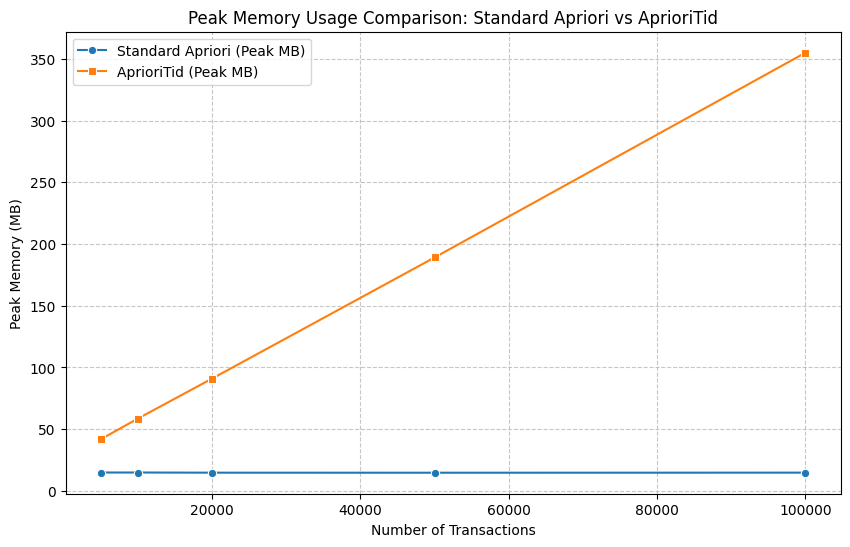

In [29]:
plt.figure(figsize=(10, 6))
sns.lineplot(data=dfA, x='n_transactions', y='Apriori_peak_mb', marker='o', label='Standard Apriori (Peak MB)')
sns.lineplot(data=dfA, x='n_transactions', y='AprioriTid_peak_mb', marker='s', label='AprioriTid (Peak MB)')

plt.title('Peak Memory Usage Comparison: Standard Apriori vs AprioriTid')
plt.xlabel('Number of Transactions')
plt.ylabel('Peak Memory (MB)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

### Trade-offs: Standard Apriori vs. AprioriTid

Based on our comprehensive benchmarks, here are the empirical and structural trade-offs between the two algorithms:

#### 1. Execution Time (CPU Performance)
* **Standard Apriori** significantly outperforms **AprioriTid** as the dataset size scales. For example, at 5,000 transactions, standard Apriori ran in **~0.27 seconds** compared to **~1.23 seconds** for AprioriTid.
* **Reasoning**: AprioriTid avoids scanning the original database at each step, but creating, traversing, and slicing nested Python structures (such as lists/dictionaries of Transaction Identifiers, or TIDs) for candidate itemsets incurs massive computational overhead in Python.

#### 2. Memory Footprint (Space Complexity)
* **Standard Apriori** maintains an extremely low and stable memory footprint because it only stores candidate counts dynamically without keeping complex transaction mappings.
* **AprioriTid** requires storing the TID-lists representing the support structure of all candidates at each step. This scales heavily with transaction volume, showing memory consumption ratios up to **24 times higher** than standard Apriori as transactions reach 100,000.

#### 3. Database Scans (I/O Complexity)
* **AprioriTid** wins on I/O minimization because it scans the original database **exactly once** (during the $k=1$ phase) to establish candidate lists. Every subsequent candidate support count is evaluated strictly using generated TID sets.
* **Standard Apriori** must scan the entire database at **every pass** ($k$ scans) to calculate support counts.

### Summary Recommendation
* **Use Standard Apriori** (or alternative frameworks like FP-Growth) for typical in-memory Python operations on large-volume transactions where memory and raw execution time are constraints.
* **Use AprioriTid** primarily in physical distributed systems (e.g., MapReduce/Hadoop setups) or slow-storage disk environments where reading the database from disk (I/O block costs) is vastly more expensive than local CPU and RAM processing.